In [1]:
# EXPLORATORY DATA ANALYSIS


import json
import logging
import random

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

# Logging configuration
logging.basicConfig(
    level=logging.INFO,
    format="[%(asctime)s] %(levelname)s: %(message)s"
)

logger = logging.getLogger("WriterLens.EDA")

# Find project root automatically
current_path = Path.cwd()

PROJECT_ROOT = next(
    (
        path
        for path in [current_path, *current_path.parents]
        if (path / "config" / "config.yaml").exists()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate WriterLens project root."
    )

print("Project root:", PROJECT_ROOT)
print("EDA environment initialized successfully.")

Project root: c:\Users\Greesha Vaishnavi\Desktop\dsprojects\Handwriting_Verification_Using_Siamese_Neural_Networks
EDA environment initialized successfully.


In [2]:
# LOAD DATA INGESTION AND VALIDATION REPORTS


INGESTION_DIR = PROJECT_ROOT / "artifacts" / "data_ingestion"

VALIDATION_DIR = PROJECT_ROOT / "artifacts" / "data_validation"

EDA_DIR = PROJECT_ROOT / "artifacts" / "eda"

PLOT_DIR = EDA_DIR / "plots"

# Create EDA artifact directories
PLOT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Load Phase 01 reports
inventory_df = pd.read_csv(
    INGESTION_DIR / "dataset_inventory.csv"
)

image_df = pd.read_csv(
    INGESTION_DIR / "image_inspection.csv"
)

xml_df = pd.read_csv(
    INGESTION_DIR / "xml_annotation_inspection.csv"
)

# Load Phase 01 summary
with open(
    INGESTION_DIR / "ingestion_summary.json",
    "r",
    encoding="utf-8"
) as file:

    ingestion_summary = json.load(file)

# Load Phase 02 writer statistics
writer_df = pd.read_csv(
    VALIDATION_DIR / "writer_statistics.csv"
)

# Load resolved XML-image references
resolved_reference_df = pd.read_csv(
    VALIDATION_DIR / "resolved_image_references.csv"
)

print("All Phase 01 and Phase 02 reports loaded successfully.")

All Phase 01 and Phase 02 reports loaded successfully.


In [3]:
# DATASET OVERVIEW


print("=" * 60)
print("WRITERLENS — DATASET OVERVIEW")
print("=" * 60)

print("\n1. Dataset Inventory")
print("Shape:", inventory_df.shape)
display(inventory_df.head())

print("\n2. Image Inspection")
print("Shape:", image_df.shape)
display(image_df.head())

print("\n3. XML Inspection")
print("Shape:", xml_df.shape)
display(xml_df.head())

print("\n4. Writer Statistics")
print("Shape:", writer_df.shape)
display(writer_df.head())

print("\n5. Resolved Image References")
print("Shape:", resolved_reference_df.shape)
display(resolved_reference_df.head())

WRITERLENS — DATASET OVERVIEW

1. Dataset Inventory
Shape: (8, 6)


,Split,Category,Folder_Exists,File_Count,Total_Size_MB,Extensions
0,train,pages,True,189,281.53,.tif
1,train,lines,True,1624,149.46,.tif
2,train,words,True,12147,133.93,.tif
3,train,xml,True,189,8.13,.xml
4,test,pages,True,1415,2185.76,.tif



2. Image Inspection
Shape: (114981, 12)


,Split,Category,Image_Name,Image_Path,Extension,Width,Height,Channels,Color_Mode,Image_Format,Is_Valid,Error
0,train,pages,0001-1.tif,C:\Users\Greesha Vaishnavi\Desktop\dsprojects\...,.tif,2499,3520,3,RGB,TIFF,True,NaN
1,train,pages,0001-2.tif,C:\Users\Greesha Vaishnavi\Desktop\dsprojects\...,.tif,2523,3537,3,RGB,TIFF,True,NaN
2,train,pages,0001-3.tif,C:\Users\Greesha Vaishnavi\Desktop\dsprojects\...,.tif,2497,3519,3,RGB,TIFF,True,NaN
3,train,pages,0001-4.tif,C:\Users\Greesha Vaishnavi\Desktop\dsprojects\...,.tif,2492,3516,3,RGB,TIFF,True,NaN
4,train,pages,0001-6.tif,C:\Users\Greesha Vaishnavi\Desktop\dsprojects\...,.tif,2523,3537,3,RGB,TIFF,True,NaN



3. XML Inspection
Shape: (1604, 14)


,Split,XML_File,Root_Tag,Writer_ID,Writer_ID_Source,Image_Reference,Image_Width,Image_Height,Text_Line_Count,Region_Count,Point_Count,Transcription_Available,Is_Valid,Error
0,train,0001-1_attributes.xml,PcGts,1,Filename inference,0001-1.tif,2480,3507,40,132,528,False,True,NaN
1,train,0001-2_attributes.xml,PcGts,1,Filename inference,0001-2.tif,2480,3507,25,75,300,False,True,NaN
2,train,0001-3_attributes.xml,PcGts,1,Filename inference,0001-3.tif,2480,3507,27,101,404,False,True,NaN
3,train,0001-4_attributes.xml,PcGts,1,Filename inference,0001-4.tif,2480,3507,27,72,288,False,True,NaN
4,train,0001-6_attributes.xml,PcGts,1,Filename inference,0001-6.tif,2480,3507,31,78,312,False,True,NaN



4. Writer Statistics
Shape: (310, 6)


,Split,Writer_ID,Sample_Count,XML_Count,Split_Writer_Count,Eligible_For_Positive_Pairs
0,test,52,5,5,283,True
1,test,53,5,5,283,True
2,test,57,5,5,283,True
3,test,58,5,5,283,True
4,test,59,5,5,283,True



5. Resolved Image References
Shape: (1604, 7)


,Split,XML_File,Writer_ID,Original_Image_Reference,Resolved_Image_Name,Resolved_Image_Path,Resolution_Method
0,train,0001-1_attributes.xml,1,0001-1.tif,0001-1.tif,C:\Users\Greesha Vaishnavi\Desktop\dsprojects\...,original_reference
1,train,0001-2_attributes.xml,1,0001-2.tif,0001-2.tif,C:\Users\Greesha Vaishnavi\Desktop\dsprojects\...,original_reference
2,train,0001-3_attributes.xml,1,0001-3.tif,0001-3.tif,C:\Users\Greesha Vaishnavi\Desktop\dsprojects\...,original_reference
3,train,0001-4_attributes.xml,1,0001-4.tif,0001-4.tif,C:\Users\Greesha Vaishnavi\Desktop\dsprojects\...,original_reference
4,train,0001-6_attributes.xml,1,0001-6.tif,0001-6.tif,C:\Users\Greesha Vaishnavi\Desktop\dsprojects\...,original_reference


In [4]:
# IMAGE DISTRIBUTION BY SPLIT AND CATEGORY


category_distribution = (
    image_df
    .groupby(["Split", "Category"])
    .size()
    .reset_index(name="Image_Count")
)

display(category_distribution)

print("\nTotal images:", len(image_df))

print("\nImages by category:")

display(
    image_df["Category"]
    .value_counts()
)

print("\nImages by split:")

display(
    image_df["Split"]
    .value_counts()
)

,Split,Category,Image_Count
0,test,lines,11849
1,test,pages,1415
2,test,words,87757
3,train,lines,1624
4,train,pages,189
5,train,words,12147



Total images: 114981

Images by category:


Category
words    99904
lines    13473
pages     1604
Name: count, dtype: int64


Images by split:


Split
test     101021
train     13960
Name: count, dtype: int64

In [5]:

# DETAILED IMAGE CATEGORY DISTRIBUTION

category_summary = (
    image_df
    .groupby(["Split", "Category"])
    .agg(
        Image_Count=("Image_Name", "count"),
        Unique_Extensions=("Extension", "nunique"),
        Average_Width=("Width", "mean"),
        Average_Height=("Height", "mean"),
        Invalid_Images=("Is_Valid", lambda x: (~x.astype(bool)).sum())
    )
    .reset_index()
)

display(category_summary)

print("\nTOTAL IMAGE COUNT:", len(image_df))

print("\nCATEGORY COUNTS:")
display(
    image_df["Category"]
    .value_counts()
    .rename_axis("Category")
    .reset_index(name="Image_Count")
)

print("\nSPLIT COUNTS:")
display(
    image_df["Split"]
    .value_counts()
    .rename_axis("Split")
    .reset_index(name="Image_Count")
)


,Split,Category,Image_Count,Unique_Extensions,Average_Width,Average_Height,Invalid_Images
0,test,lines,11849,1,1650.819985,123.910879,0
1,test,pages,1415,1,2538.416961,3547.965371,0
2,test,words,87757,1,183.830566,80.824436,0
3,train,lines,1624,1,1639.365148,125.655172,0
4,train,pages,189,1,2509.656085,3527.867725,0
5,train,words,12147,1,172.629456,79.084877,0



TOTAL IMAGE COUNT: 114981

CATEGORY COUNTS:


,Category,Image_Count
0,words,99904
1,lines,13473
2,pages,1604



SPLIT COUNTS:


,Split,Image_Count
0,test,101021
1,train,13960


In [6]:

# IMAGE DIMENSION ANALYSIS

image_df["Aspect_Ratio"] = (
    image_df["Width"] / image_df["Height"]
)

dimension_summary = (
    image_df
    .groupby("Category")
    .agg(
        Count=("Image_Name", "count"),
        Min_Width=("Width", "min"),
        Max_Width=("Width", "max"),
        Mean_Width=("Width", "mean"),
        Min_Height=("Height", "min"),
        Max_Height=("Height", "max"),
        Mean_Height=("Height", "mean"),
        Mean_Aspect_Ratio=("Aspect_Ratio", "mean")
    )
    .round(2)
    .reset_index()
)

display(dimension_summary)


,Category,Count,Min_Width,Max_Width,Mean_Width,Min_Height,Max_Height,Mean_Height,Mean_Aspect_Ratio
0,lines,13473,10,2387,1649.44,5,323,124.12,13.70
1,pages,1604,2480,2663,2535.03,3507,3634,3545.60,0.71
2,words,99904,10,1593,182.47,11,239,80.61,2.38


In [7]:

# WRITER DISTRIBUTION ANALYSIS

print("=" * 65)
print("WRITER DISTRIBUTION ANALYSIS")
print("=" * 65)

# Number of unique writers in each split
writer_distribution = (
    writer_df
    .groupby("Split")
    .agg(
        Unique_Writers=("Writer_ID", "nunique"),
        Total_Samples=("Sample_Count", "sum"),
        Average_Samples_Per_Writer=("Sample_Count", "mean"),
        Minimum_Samples=("Sample_Count", "min"),
        Maximum_Samples=("Sample_Count", "max")
    )
    .round(2)
)

display(writer_distribution)

# Overall writer statistics
print("\nTotal unique writers:", writer_df["Writer_ID"].nunique())
print("Total writer groups:", len(writer_df))

print("\nSamples per writer:")
display(
    writer_df["Sample_Count"]
    .describe()
    .round(2)
)


WRITER DISTRIBUTION ANALYSIS


,Unique_Writers,Total_Samples,Average_Samples_Per_Writer,Minimum_Samples,Maximum_Samples
Split,,,,,
test,283,1415,5.0,5,5
train,27,189,7.0,7,7



Total unique writers: 310
Total writer groups: 310

Samples per writer:


count    310.00
mean       5.17
std        0.56
min        5.00
25%        5.00
50%        5.00
75%        5.00
max        7.00
Name: Sample_Count, dtype: float64

In [8]:

# WRITER OVERLAP ANALYSIS

train_writers = set(
    writer_df.loc[
        writer_df["Split"].str.lower() == "train",
        "Writer_ID"
    ].astype(str)
)

test_writers = set(
    writer_df.loc[
        writer_df["Split"].str.lower() == "test",
        "Writer_ID"
    ].astype(str)
)

common_writers = train_writers.intersection(test_writers)

train_only_writers = train_writers - test_writers
test_only_writers = test_writers - train_writers

print("Train writers:", len(train_writers))
print("Test writers:", len(test_writers))
print("Common writers:", len(common_writers))
print("Train-only writers:", len(train_only_writers))
print("Test-only writers:", len(test_only_writers))

if common_writers:
    print("\nWARNING: Writer overlap detected.")
    print("Common writer IDs:", sorted(common_writers))
else:
    print("\nNo writer overlap detected.")
    print("The current split is writer-disjoint.")


Train writers: 27
Test writers: 283
Common writers: 0
Train-only writers: 27
Test-only writers: 283

No writer overlap detected.
The current split is writer-disjoint.


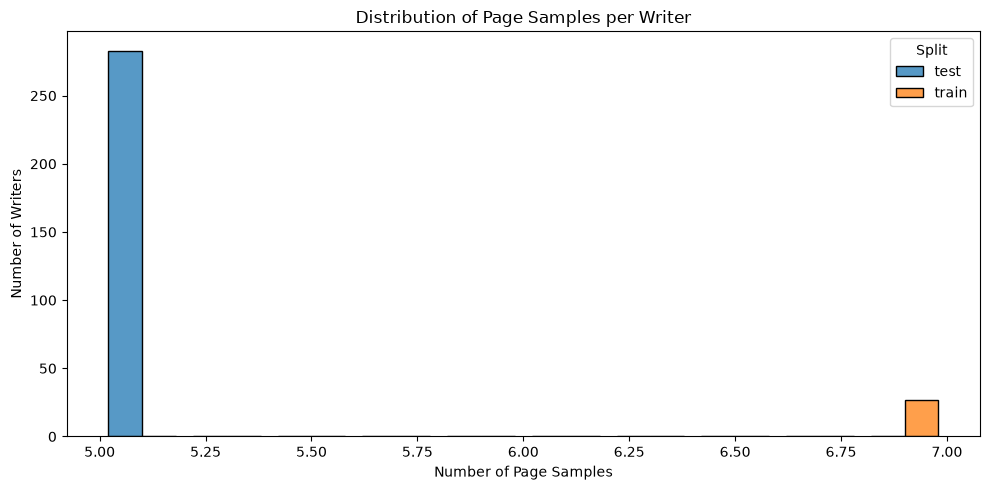

In [9]:

# WRITER SAMPLE DISTRIBUTION

plt.figure(figsize=(10, 5))

sns.histplot(
    data=writer_df,
    x="Sample_Count",
    hue="Split",
    bins=10,
    multiple="dodge",
    shrink=0.8
)

plt.title("Distribution of Page Samples per Writer")
plt.xlabel("Number of Page Samples")
plt.ylabel("Number of Writers")
plt.tight_layout()

plt.savefig(
    PLOT_DIR / "writer_sample_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [10]:

# SAVE WRITER DISTRIBUTION ANALYSIS

writer_distribution_report = {
    "total_unique_writers": int(writer_df["Writer_ID"].nunique()),
    "train_writers": len(train_writers),
    "test_writers": len(test_writers),
    "common_writers": len(common_writers),
    "train_only_writers": len(train_only_writers),
    "test_only_writers": len(test_only_writers),
    "writer_disjoint": len(common_writers) == 0
}

with open(
    EDA_DIR / "writer_distribution_summary.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        writer_distribution_report,
        file,
        indent=4
    )

print("Writer distribution report saved successfully.")
print(writer_distribution_report)


Writer distribution report saved successfully.
{'total_unique_writers': 310, 'train_writers': 27, 'test_writers': 283, 'common_writers': 0, 'train_only_writers': 27, 'test_only_writers': 283, 'writer_disjoint': True}


In [11]:

# IMAGE DIMENSION AND ASPECT RATIO ANALYSIS

# Create a copy so the original inspection DataFrame remains unchanged
dimension_df = image_df.copy()

# Ensure dimensions are numeric
dimension_df["Width"] = pd.to_numeric(
    dimension_df["Width"], errors="coerce"
)

dimension_df["Height"] = pd.to_numeric(
    dimension_df["Height"], errors="coerce"
)

# Calculate aspect ratio
dimension_df["Aspect_Ratio"] = (
    dimension_df["Width"] / dimension_df["Height"]
)

# Calculate total pixels
dimension_df["Pixel_Count"] = (
    dimension_df["Width"] * dimension_df["Height"]
)

# Summarize dimensions by image category
dimension_summary = (
    dimension_df
    .groupby("Category")
    .agg(
        Image_Count=("Image_Name", "count"),
        Min_Width=("Width", "min"),
        Max_Width=("Width", "max"),
        Mean_Width=("Width", "mean"),
        Median_Width=("Width", "median"),
        Min_Height=("Height", "min"),
        Max_Height=("Height", "max"),
        Mean_Height=("Height", "mean"),
        Median_Height=("Height", "median"),
        Mean_Aspect_Ratio=("Aspect_Ratio", "mean"),
        Median_Aspect_Ratio=("Aspect_Ratio", "median"),
        Mean_Pixel_Count=("Pixel_Count", "mean")
    )
    .round(2)
    .reset_index()
)

display(dimension_summary)


,Category,Image_Count,Min_Width,Max_Width,Mean_Width,Median_Width,Min_Height,Max_Height,Mean_Height,Median_Height,Mean_Aspect_Ratio,Median_Aspect_Ratio,Mean_Pixel_Count
0,lines,13473,10,2387,1649.44,1763.0,5,323,124.12,124.0,13.70,13.55,207081.76
1,pages,1604,2480,2663,2535.03,2532.0,3507,3634,3545.60,3544.0,0.71,0.71,8989151.83
2,words,99904,10,1593,182.47,162.0,11,239,80.61,79.0,2.38,2.15,15745.35


In [12]:

# SAVE IMAGE DIMENSION ANALYSIS

dimension_summary.to_csv(
    EDA_DIR / "image_dimension_summary.csv",
    index=False
)

print("Image dimension summary saved successfully.")
print("Output:", EDA_DIR / "image_dimension_summary.csv")


Image dimension summary saved successfully.
Output: c:\Users\Greesha Vaishnavi\Desktop\dsprojects\Handwriting_Verification_Using_Siamese_Neural_Networks\artifacts\eda\image_dimension_summary.csv


In [13]:

# PIXEL INTENSITY ANALYSIS - SAMPLE SELECTION

# Select only images marked valid
valid_image_df = image_df[
    image_df["Is_Valid"].astype(str).str.lower().isin(
        ["true", "1"]
    )
].copy()

# Sample up to 150 images from each category
pixel_sample_df = (
    valid_image_df
    .groupby("Category", group_keys=False)
    .apply(
        lambda group: group.sample(
            n=min(150, len(group)),
            random_state=42
        )
    )
    .reset_index(drop=True)
)

print("Total sampled images:", len(pixel_sample_df))

print("\nSamples by category:")
display(pixel_sample_df["Category"].value_counts())


Total sampled images: 450

Samples by category:


KeyError: 'Category'

In [ ]:

# EXTRACT PIXEL INTENSITY STATISTICS

from PIL import Image
import numpy as np

pixel_statistics = []

for _, row in pixel_sample_df.iterrows():

    image_path = Path(row["Image_Path"])

    try:
        with Image.open(image_path) as img:

            # Convert to grayscale
            gray_image = img.convert("L")

            # Resize while preserving aspect ratio
            gray_image.thumbnail((512, 512))

            # Convert image into NumPy array
            pixels = np.asarray(gray_image)

            pixel_statistics.append({
                "Split": row["Split"],
                "Category": row["Category"],
                "Image_Name": row["Image_Name"],
                "Mean_Intensity": float(np.mean(pixels)),
                "Median_Intensity": float(np.median(pixels)),
                "Std_Intensity": float(np.std(pixels)),
                "Min_Intensity": int(np.min(pixels)),
                "Max_Intensity": int(np.max(pixels)),
                "P05_Intensity": float(np.percentile(pixels, 5)),
                "P95_Intensity": float(np.percentile(pixels, 95))
            })

    except Exception as error:
        logger.warning(
            "Could not analyse %s: %s",
            image_path,
            error
        )

pixel_stats_df = pd.DataFrame(pixel_statistics)

print("Successfully analysed images:", len(pixel_stats_df))

display(pixel_stats_df.head())
